# FashionMNIST Neural Network

Kenny Gallardo

## Dataset overview

FashionMNIST contains 70,000 grayscale images of clothing items in 10 categories. Each image is 28 ? 28 pixels; the pixel values are the input features the neural network uses to recognize an item. The label is the correct clothing category, which the model learns to predict for each image.


In [19]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

In [20]:
# Define transformations (Convert PIL image to Tensor and normalize)
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

# Download and load Training Data
train_set = datasets.FashionMNIST(root='~/data', train=True, download=True, transform=transform)

# Download and load Test Data
test_set = datasets.FashionMNIST(root='~/data', train=False, download=True, transform=transform)

print(f"Training set size: {len(train_set)}")
print(f"Test set size: {len(test_set)}")

#Setup dataloaders for training and test sets
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

Training set size: 60000
Test set size: 10000


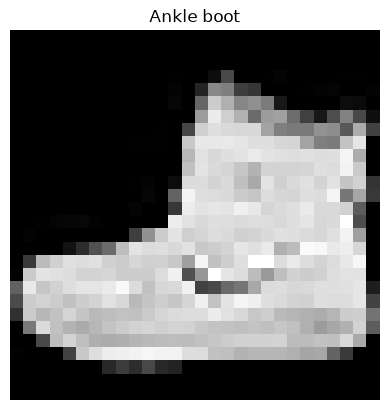

In [21]:
# Labels for the DataSet
FASHION_MNIST_CLASSES = [
    "T-shirt/top",  # Index 0
    "Trouser",      # Index 1
    "Pullover",     # Index 2
    "Dress",        # Index 3
    "Coat",         # Index 4
    "Sandal",       # Index 5
    "Shirt",        # Index 6
    "Sneaker",      # Index 7
    "Bag",          # Index 8
    "Ankle boot"    # Index 9
]

image, label = train_set[0]
plt.imshow(image.squeeze(), cmap="gray")
plt.title(FASHION_MNIST_CLASSES[label])
plt.axis("off")
plt.show()

What transforms.ToTensor() does.
The transforms.ToTensor() function converts each FashionMNIST image from a PIL image into a PyTorch tensor, rearranges its dimensions to channels × height × width, and scales pixel values from 0–255 to 0.0–1.0. Each grayscale image becomes a tensor with the shape (1, 28, 28), allowing PyTorch neural networks to process the images.

Why the images are normalized.
transforms.Normalize((0.5,), (0.5,)) converts the pixel values from the [0, 1] range produced by ToTensor() to approximately [-1, 1]. Centering the data around zero gives all inputs a consistent scale, which helps gradients remain stable, improves training efficiency, and often allows the neural network to converge faster and achieve better performance. The same normalization is applied to both the training and testing datasets so the model receives data in a consistent format during training and evaluation.

Why the training data is shuffled.
The training DataLoader uses shuffle=True to reorder the training images randomly at the start of every epoch, so each mini-batch is a different, diverse mix of classes. Consecutive images in a dataset often share a class or similar features, and shuffling breaks that correlation. This prevents the model from learning patterns tied to the order of the data, keeps the gradient estimates from each batch closer to unbiased estimates of the true gradient, and encourages the model to learn general relationships between image features and clothing categories, which improves its ability to classify images it has not seen before.

Why the testing data is not shuffled.
shuffle=False is used for the test DataLoader because evaluation does not involve weight updates, making sample order irrelevant to overall metrics like loss or accuracy. Keeping the test data in a fixed order ensures fully reproducible results across runs and simplifies debugging by allowing you to easily trace predictions back to specific test indices to analyze misclassifications or build confusion matrices.

In [22]:
# Define the neural network
class FashionMNIST_Network(nn.Module):
    def __init__(self):
        super(FashionMNIST_Network, self).__init__()

        # Input layer: 28 x 28 image = 784 input features
        self.input_layer = nn.Linear(28 * 28, 128)

        # Hidden layer
        self.hidden_layer = nn.Linear(128, 64)

        # Output layer: 10 clothing categories
        self.output_layer = nn.Linear(64, 10)

    def forward(self, x):
        # Flatten the image into 784 input features
        x = x.view(x.size(0), -1)

        # Input layer with ReLU activation
        x = F.relu(self.input_layer(x))

        # Hidden layer with ReLU activation
        x = F.relu(self.hidden_layer(x))

        # Output layer
        x = self.output_layer(x)

        return x


# Create the neural network
model = FashionMNIST_Network()

# Display the model architecture
print(model)

FashionMNIST_Network(
  (input_layer): Linear(in_features=784, out_features=128, bias=True)
  (hidden_layer): Linear(in_features=128, out_features=64, bias=True)
  (output_layer): Linear(in_features=64, out_features=10, bias=True)
)


In [23]:
# softmax tester batch
images, labels = next(iter(train_loader))
outputs = model(images)
print(outputs.shape)  # should be torch.Size([64, 10])
# Apply softmax to get probabilities
probabilities = F.softmax(outputs, dim=1)
print(probabilities.shape)  # should be torch.Size([64, 10])
print(probabilities[0])  # print the probabilities for the first image in the batch
print(probabilities[0].sum())  # should be 1.0, as softmax outputs probabilities that sum to 1

torch.Size([64, 10])
torch.Size([64, 10])
tensor([0.1249, 0.0847, 0.0860, 0.0892, 0.1051, 0.1266, 0.1047, 0.0943, 0.0979,
        0.0866], grad_fn=<SelectBackward0>)
tensor(1.0000, grad_fn=<SumBackward0>)


In [24]:
# Loss function: multi-class classification with 10 categories
criterion = nn.CrossEntropyLoss()

# Optimizer: updates the model's parameters using the gradients
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Loss function:", criterion)
print("Optimizer:", optimizer)  

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [25]:
# Train the model using mini-batches
num_epochs = 5

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    print(f"Epoch {epoch + 1}/{num_epochs}, Loss: {epoch_loss:.4f}")


Epoch 1/5, Loss: 0.5132
Epoch 2/5, Loss: 0.3742
Epoch 3/5, Loss: 0.3375
Epoch 4/5, Loss: 0.3125
Epoch 5/5, Loss: 0.2950


In [26]:
# Evaluate classification accuracy on the held-out test dataset
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

test_accuracy = 100 * correct / total
print(f"Test accuracy: {test_accuracy:.2f}% ({correct}/{total})")


Test accuracy: 87.96% (8796/10000)


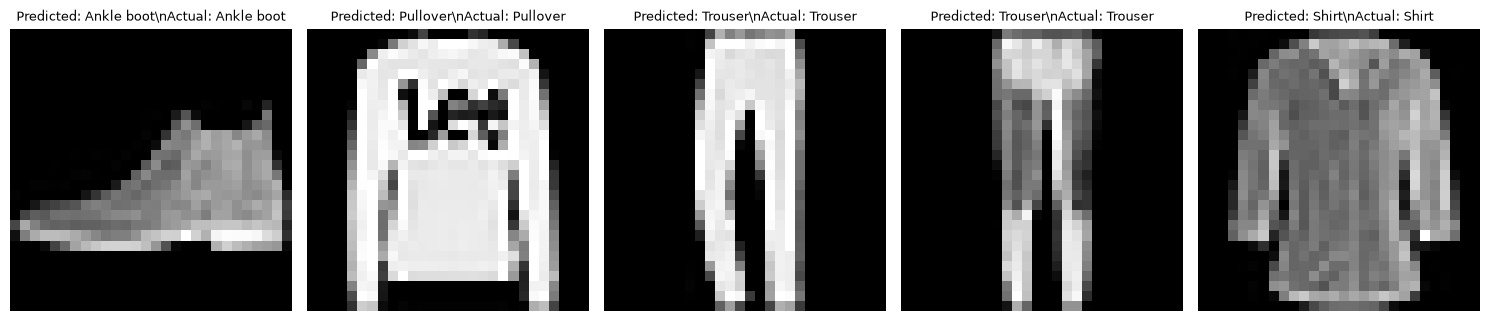

In [27]:
# Display five test images with predicted and correct clothing categories
model.eval()
images, labels = next(iter(test_loader))

with torch.no_grad():
    outputs = model(images)
    predictions = outputs.argmax(dim=1)

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, ax in enumerate(axes):
    # Undo normalization for display: [-1, 1] -> [0, 1]
    image_to_display = images[i].squeeze().cpu() * 0.5 + 0.5
    true_label = FASHION_MNIST_CLASSES[labels[i].item()]
    predicted_label = FASHION_MNIST_CLASSES[predictions[i].item()]

    ax.imshow(image_to_display, cmap="gray")
    ax.set_title(f"Predicted: {predicted_label}\\nActual: {true_label}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [29]:
# Calculate test accuracy for each clothing category
num_classes = len(FASHION_MNIST_CLASSES)
class_correct = torch.zeros(num_classes, dtype=torch.long)
class_total = torch.zeros(num_classes, dtype=torch.long)
confusion_matrix = torch.zeros(num_classes, num_classes, dtype=torch.long)

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        for true_label, predicted_label in zip(labels, predictions):
            class_total[true_label] += 1
            if true_label == predicted_label:
                class_correct[true_label] += 1
            confusion_matrix[true_label, predicted_label] += 1

class_accuracies = class_correct.float() / class_total.clamp(min=1)
print("Test accuracy by category:")
for category_index, category in enumerate(FASHION_MNIST_CLASSES):
    print(f"{category}: {100 * class_accuracies[category_index].item():.2f}%")

hardest_indices = torch.argsort(class_accuracies)[:3].tolist()
print("\nThree categories with the lowest test accuracy:")
for category_index in hardest_indices:
    print(
        f"{FASHION_MNIST_CLASSES[category_index]}: "
        f"{100 * class_accuracies[category_index].item():.2f}%"
    )

print("\nConfusion matrix (rows = actual labels, columns = predicted labels):")
print(confusion_matrix)

Test accuracy by category:
T-shirt/top: 82.30%
Trouser: 96.90%
Pullover: 75.80%
Dress: 90.50%
Coat: 83.70%
Sandal: 92.80%
Shirt: 68.50%
Sneaker: 96.60%
Bag: 98.10%
Ankle boot: 94.40%

Three categories with the lowest test accuracy:
Shirt: 68.50%
Pullover: 75.80%
T-shirt/top: 82.30%

Confusion matrix (rows = actual labels, columns = predicted labels):
tensor([[823,   1,  14,  48,   2,   0,  98,   0,  14,   0],
        [  1, 969,   0,  24,   2,   0,   3,   0,   1,   0],
        [ 20,   0, 758,  16, 106,   0,  95,   0,   5,   0],
        [ 22,   8,   7, 905,  31,   0,  21,   0,   6,   0],
        [  0,   1,  61,  36, 837,   0,  59,   0,   6,   0],
        [  0,   0,   0,   1,   0, 928,   0,  47,   8,  16],
        [127,   0,  61,  36,  69,   0, 685,   0,  22,   0],
        [  0,   0,   0,   0,   0,  13,   0, 966,   1,  20],
        [  3,   0,   1,   5,   2,   1,   3,   4, 981,   0],
        [  0,   0,   0,   0,   0,   9,   1,  46,   0, 944]])
